# EDA — Online Retail II (UK gift wholesaler)

Quick exploration behind the retention dashboard. Dataset: [Online Retail II on Kaggle](https://www.kaggle.com/datasets/lakshmi25npathi/online-retail-dataset) (real transactions of a UK-based online gift wholesaler, Dec 2009 – Dec 2011, originally published by Dr Daqing Chen, London South Bank University, UCI dataset #502).

Each row is one line item on an invoice: invoice number, stock code, description, quantity, invoice date/time, unit price, customer ID, country.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PATH = r"../online_retail_II.xlsx"
dfs = [pd.read_excel(PATH, sheet_name=s) for s in ["Year 2009-2010", "Year 2010-2011"]]
df = pd.concat(dfs, ignore_index=True)
df.columns = [c.strip().replace(" ", "_").lower() for c in df.columns]
print("raw shape:", df.shape)
df.head()

raw shape: (1067371, 8)


,invoice,stockcode,description,quantity,invoicedate,price,customer_id,country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [2]:
print("missing values:\n", df.isna().sum())
n_cancel = df["invoice"].astype(str).str.startswith("C").sum()
print(f"\ncancellation invoices (start with 'C'): {n_cancel} ({n_cancel/len(df):.1%})")
print(f"rows without customer_id: {df['customer_id'].isna().sum()} ({df['customer_id'].isna().mean():.1%})")
print("\nquantity range:", df["quantity"].min(), "to", df["quantity"].max())
print("price range:", df["price"].min(), "to", df["price"].max())

missing values:
 invoice             0
stockcode           0
description      4382
quantity            0
invoicedate         0
price               0
customer_id    243007
country             0
dtype: int64

cancellation invoices (start with 'C'): 19494 (1.8%)
rows without customer_id: 243007 (22.8%)

quantity range: -80995 to 80995
price range: -53594.36 to 38970.0


**What is dirty here (and how the dashboard handles it):**

- ~23% of rows have **no customer ID** — anonymous retail walk-ins. They cannot be 'called back', so they are excluded from a retention dashboard. A revenue chart that silently mixed them in would overstate the identifiable customer base.
- **Cancellations** (invoices starting with `C`, negative quantities) are ~2% of rows. Counted as sales they would inflate both revenue and a customer's value, so they are excluded — and the app says so in a caption.
- Extreme quantities (tens of thousands of units) are real wholesale orders, not errors. They make **means lie**, so the app reports medians where a typical value is shown.

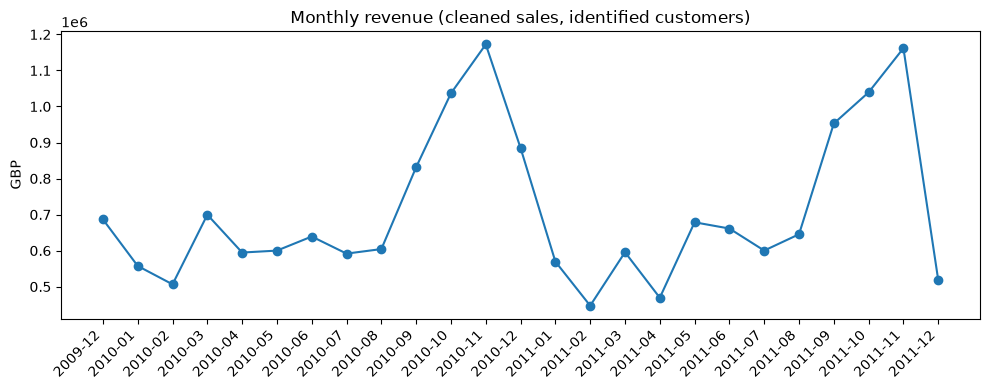

In [3]:
sales = df[~df["invoice"].astype(str).str.startswith("C")].copy()
sales = sales[(sales["quantity"] > 0) & (sales["price"] > 0)].dropna(subset=["customer_id"])
sales["revenue"] = sales["quantity"] * sales["price"]
sales["month"] = pd.to_datetime(sales["invoicedate"]).dt.to_period("M").astype(str)

monthly = sales.groupby("month")["revenue"].sum()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly.index, monthly.values, marker="o")
ax.set_title("Monthly revenue (cleaned sales, identified customers)")
ax.set_ylabel("GBP")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**The seasonal story:** revenue peaks in **October–November** (over £1M), not December — retailers stock up *before* Christmas, so a wholesaler's season ends earlier than a consumer shop's. **December 2011 is a partial month** (data ends 9 Dec) — its bar looks like a crash but is only 9 days of trading; the dashboard marks it as incomplete.

customers: 5878
A-tier (top 10% by value): 588 customers holding 63.9% of all revenue


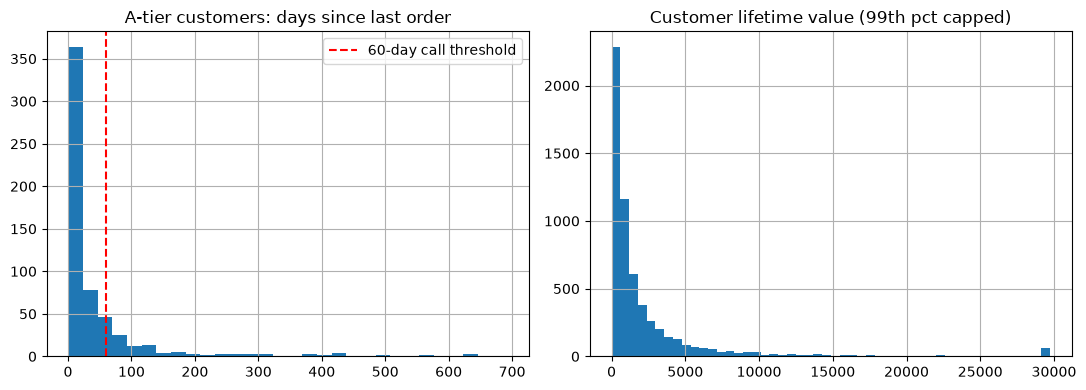


call list: 115 A-tier customers silent > 60 days


,last_order,frequency,monetary,recency_days,tier
customer_id,,,,,
12346.0,2011-01-18 10:01:00,12,77556.46,326,A
16754.0,2010-12-02 17:38:00,29,67502.47,372,A
17850.0,2010-12-02 15:27:00,155,56600.08,372,A
13093.0,2011-03-09 12:14:00,55,54943.65,276,A
15749.0,2011-04-18 13:20:00,3,44534.30,235,A
15098.0,2011-06-10 15:33:00,3,39916.50,182,A
13902.0,2010-03-17 13:09:00,5,34095.26,632,A
18251.0,2011-09-13 15:03:00,9,26278.86,87,A
13802.0,2011-07-24 10:54:00,19,26259.11,139,A


In [4]:
snapshot = pd.to_datetime(sales["invoicedate"]).max() + pd.Timedelta(days=1)
rfm = sales.groupby("customer_id").agg(
    last_order=("invoicedate", "max"),
    frequency=("invoice", "nunique"),
    monetary=("revenue", "sum"))
rfm["recency_days"] = (snapshot - pd.to_datetime(rfm["last_order"])).dt.days
q90, q70 = rfm["monetary"].quantile(0.9), rfm["monetary"].quantile(0.7)
rfm["tier"] = np.where(rfm["monetary"] >= q90, "A", np.where(rfm["monetary"] >= q70, "B", "C"))

print("customers:", len(rfm))
print("A-tier (top 10% by value):", (rfm['tier']=='A').sum(),
      "customers holding", f"{rfm.loc[rfm['tier']=='A','monetary'].sum()/rfm['monetary'].sum():.1%}",
      "of all revenue")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
rfm[rfm["tier"] == "A"]["recency_days"].hist(ax=axes[0], bins=30)
axes[0].axvline(60, color="red", ls="--", label="60-day call threshold")
axes[0].set_title("A-tier customers: days since last order")
axes[0].legend()
rfm["monetary"].clip(upper=rfm["monetary"].quantile(0.99)).hist(ax=axes[1], bins=50)
axes[1].set_title("Customer lifetime value (99th pct capped)")
plt.tight_layout()
plt.show()

call_list = rfm[(rfm["tier"] == "A") & (rfm["recency_days"] > 60)].sort_values("monetary", ascending=False)
print(f"\ncall list: {len(call_list)} A-tier customers silent > 60 days")
call_list.head(10)

**What the EDA decided:**

- **Show:** the 60-day silent A-tier count (headline KPI), monthly revenue with the seasonal peak, the recency distribution of valuable customers, and the call list itself.
- **Cut:** a country map (41 countries — interesting but no call decision changes by looking at a map; a country filter is enough) and a product ranking (4,000+ stock codes — the manager calls about *customers*, not products).
- **Warn about:** the partial December 2011 month, the excluded anonymous rows, and why medians beat means here.